# Data Mining Lab Assignment: Build a Recommender System using a Medallion Data Lake

## Step 1:Data Lake setup and the Bronze Layer

In [1]:
import os, glob, zipfile, warnings
import requests
import numpy as np
import pandas as pd
from datetime import datetime, timezone

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50, "display.width", 200)

# --- data lake folders
for layer in ["bronze", "silver", "gold"]:
    os.makedirs(layer, exist_ok=True)
print("Folders:", [d for d in ["bronze", "silver", "gold"] if os.path.isdir(d)])

Folders: ['bronze', 'silver', 'gold']


In [2]:

URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
if not os.path.exists("book-crossings.zip"):
    r = requests.get(URL, timeout=300)
    r.raise_for_status()
    with open("book-crossings.zip", "wb") as f:
        f.write(r.content)

with zipfile.ZipFile("book-crossings.zip") as z:
    z.extractall("raw")

raw_files = {os.path.basename(p): p for p in glob.glob("raw/**/*.csv", recursive=True)}
print(raw_files)

{'BX-Books.csv': 'raw/BX-Books.csv', 'BX-Book-Ratings.csv': 'raw/BX-Book-Ratings.csv', 'BX-Users.csv': 'raw/BX-Users.csv'}


In [3]:
def read_raw(path):
    """Read a Book-Crossing file exactly as it is.
    - sep=';'            : semicolon separated
    - encoding='latin-1' : files are NOT UTF-8 (ISO-8859-1)
    - escapechar='\\'     : titles contain \" escaped quotes
    - dtype=str          : keep every value as the source text (no type guessing / coercion)
    - on_bad_lines='skip': a handful of malformed rows cannot be parsed
    """
    return pd.read_csv(path, sep=";", encoding="latin-1", escapechar="\\",
                       dtype=str, on_bad_lines="skip")

raw_users   = read_raw(raw_files["BX-Users.csv"])
raw_books   = read_raw(raw_files["BX-Books.csv"])
raw_ratings = read_raw(raw_files["BX-Book-Ratings.csv"])

ingestion_ts = pd.Timestamp(datetime.now(timezone.utc))
for df in (raw_users, raw_books, raw_ratings):
    df["ingestion_timestamp"] = ingestion_ts

raw_users.to_parquet("bronze/users.parquet", index=False)
raw_books.to_parquet("bronze/books.parquet", index=False)
raw_ratings.to_parquet("bronze/ratings.parquet", index=False)

print({k: v for k, v in zip(["users", "books", "ratings"],
                            [raw_users.shape, raw_books.shape, raw_ratings.shape])})
print(os.listdir("bronze"))

{'users': (278858, 4), 'books': (271379, 9), 'ratings': (1149780, 4)}
['ratings.parquet', 'books.parquet', 'users.parquet']


## Step 2: Explore the Bronze Data (EDA)

In [4]:
users   = pd.read_parquet("bronze/users.parquet")
books   = pd.read_parquet("bronze/books.parquet")
ratings = pd.read_parquet("bronze/ratings.parquet")

### Shape, data types and missing-value count of each table

In [5]:
for name, df in [("users", users), ("books", books), ("ratings", ratings)]:
    print(f"===== {name}  shape={df.shape} =====")
    summary = pd.DataFrame({"dtype": df.dtypes.astype(str),
                            "missing": df.isna().sum(),
                            "missing_%": (df.isna().mean() * 100).round(2)})
    print(summary, "\n")

===== users  shape=(278858, 4) =====
                                   dtype  missing  missing_%
User-ID                           object        0       0.00
Location                          object        0       0.00
Age                               object   110762      39.72
ingestion_timestamp  datetime64[us, UTC]        0       0.00 

===== books  shape=(271379, 9) =====
                                   dtype  missing  missing_%
ISBN                              object        0        0.0
Book-Title                        object        0        0.0
Book-Author                       object        2        0.0
Year-Of-Publication               object        0        0.0
Publisher                         object        2        0.0
Image-URL-S                       object        0        0.0
Image-URL-M                       object        0        0.0
Image-URL-L                       object        0        0.0
ingestion_timestamp  datetime64[us, UTC]        0        0.0 

===== r

**Found:** all columns are text (`object`) in Bronze; `Age` has 110,762 missing values (39.72%), `Book-Author` and `Publisher` have 2 each → **Silver:** convert columns to proper types and fill missing ages with the median.

### Distribution of ratings

Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

Zero ratings: 716,109 of 1,149,780  (62.3%)


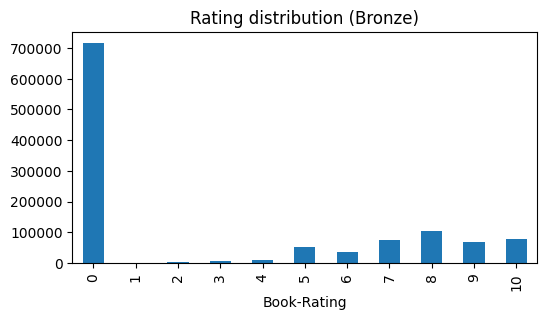

In [6]:
r = pd.to_numeric(ratings["Book-Rating"], errors="coerce")
print(r.value_counts().sort_index())
print(f"\nZero ratings: {(r == 0).sum():,} of {len(r):,}  ({(r == 0).mean():.1%})")
r.value_counts().sort_index().plot(kind="bar", title="Rating distribution (Bronze)", figsize=(6, 3));

**Found:** 716,109 of 1,149,780 ratings (62.3%) are 0, meaning no explicit rating → **Silver:** remove all 0 ratings and keep ratings 1 to 10.

### Distribution of user ages and of publication years

count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64
Age < 5   : 882
Age > 100 : 366


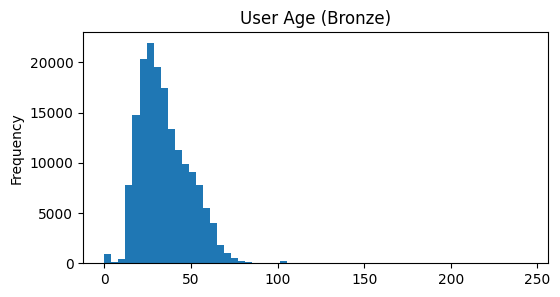

In [7]:
age = pd.to_numeric(users["Age"], errors="coerce")
print(age.describe())
print("Age < 5   :", (age < 5).sum())
print("Age > 100 :", (age > 100).sum())
age.dropna().plot(kind="hist", bins=60, title="User Age (Bronze)", figsize=(6, 3));

**Found:** ages range from 0 to 244 (882 users below 5, 366 above 100) → **Silver:** set age below 5 or above 100 to null, then fill nulls with the median age (32).

count    271379.000000
mean       1959.756050
std         258.011363
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64
Year == 0           : 4619
Year > 2026 (future) : 11
Non-numeric year    : 0


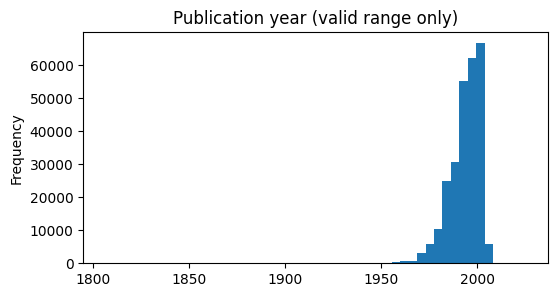

In [8]:
year = pd.to_numeric(books["Year-Of-Publication"], errors="coerce")
current_year = datetime.now().year
print(year.describe())
print("Year == 0           :", (year == 0).sum())
print(f"Year > {current_year} (future) :", (year > current_year).sum())
print("Non-numeric year    :", year.isna().sum() - books["Year-Of-Publication"].isna().sum())
year[(year > 1800) & (year <= current_year)].plot(kind="hist", bins=50, title="Publication year (valid range only)", figsize=(6, 3));

**Found:** 4,619 books have publication year 0 and 11 have future years (up to 2050) → **Silver:** set year 0 or future years to null.

### Number of ratings per user and per book

Ratings per user:
 count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
50%           1.000000
75%           4.000000
90%          12.000000
95%          29.000000
99%         174.000000
max       13602.000000
dtype: float64 

Ratings per book:
 count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
50%           1.000000
75%           2.000000
90%           6.000000
95%          10.000000
99%          36.000000
max        2502.000000
dtype: float64 

 min_ratings  users_kept_%  books_kept_%
           1        100.00        100.00
           2         43.80         42.14
           5         21.67         12.85
          10         12.44          5.38
          20          7.00          2.20
          50          3.26          0.64


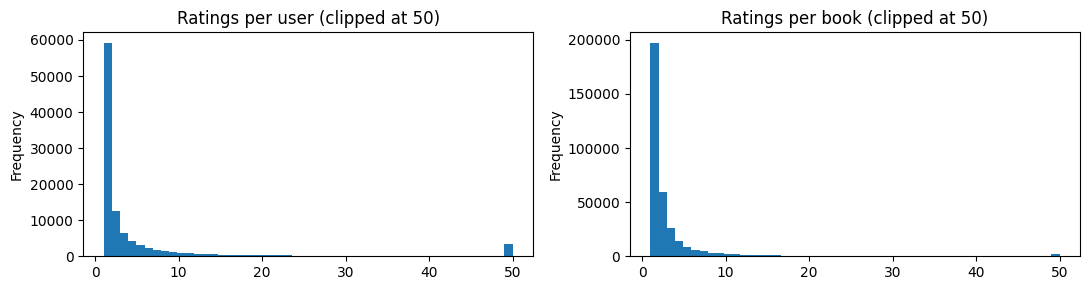

In [9]:
per_user = ratings.groupby("User-ID").size()
per_book = ratings.groupby("ISBN").size()
print("Ratings per user:\n", per_user.describe(percentiles=[.5, .75, .9, .95, .99]), "\n")
print("Ratings per book:\n", per_book.describe(percentiles=[.5, .75, .9, .95, .99]), "\n")

# Share of users / books that would survive different minimum-rating thresholds
rows = []
for t in [1, 2, 5, 10, 20, 50]:
    rows.append({"min_ratings": t,
                 "users_kept_%": round((per_user >= t).mean() * 100, 2),
                 "books_kept_%": round((per_book >= t).mean() * 100, 2)})
print(pd.DataFrame(rows).to_string(index=False))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
per_user.clip(upper=50).plot(kind="hist", bins=50, ax=ax[0], title="Ratings per user (clipped at 50)")
per_book.clip(upper=50).plot(kind="hist", bins=50, ax=ax[1], title="Ratings per book (clipped at 50)")
plt.tight_layout()

**Found:** the median user and the median book have only 1 rating, and just 12.44% of users and 5.38% of books have 10 or more → **Silver:** keep only users and books with at least 10 ratings.

### Matrix sparsity

In [10]:
n_users_r = ratings["User-ID"].nunique()
n_books_r = ratings["ISBN"].nunique()
n_ratings = len(ratings.drop_duplicates(["User-ID", "ISBN"]))
sparsity = 1 - n_ratings / (n_users_r * n_books_r)
print(f"Users with ratings: {n_users_r:,} | Books with ratings: {n_books_r:,} | Ratings: {n_ratings:,}")
print(f"Possible pairs: {n_users_r * n_books_r:,}")
print(f"Density : {(1 - sparsity) * 100:.5f}%")
print(f"Sparsity: {sparsity * 100:.4f}%  (share of user-book pairs with NO rating)")

Users with ratings: 105,283 | Books with ratings: 340,556 | Ratings: 1,149,780
Possible pairs: 35,854,757,348
Density : 0.00321%
Sparsity: 99.9968%  (share of user-book pairs with NO rating)


**Found:** the user-book matrix is 99.9968% empty (1,149,780 ratings out of 35.85 billion possible pairs) → **Silver/Gold:** filter to active users and books, and store the Gold matrix as a sparse matrix.

## Step 3: Clean the Data and Build the Silver Layer

**Threshold chosen:** at least 10 ratings per user and per book.

**Justification (from EDA):** the median user and book have only 1 rating, so most have too little data for reliable cosine similarity. A minimum of 10 keeps 12.44% of users and 5.38% of books, enough for a useful catalogue; a threshold of 20 would shrink it to 7.00% of users and 2.20% of books. It also raises the matrix density from 0.003% to 1.12%.

In [11]:
MIN_RATINGS = 10
CURRENT_YEAR = datetime.now().year

In [12]:
u = pd.read_parquet("bronze/users.parquet")
n_before = len(u)

# duplicates
u = u.drop_duplicates()
u["User-ID"] = pd.to_numeric(u["User-ID"], errors="coerce")
u = u.dropna(subset=["User-ID"]).astype({"User-ID": "int64"})
u = u.drop_duplicates(subset="User-ID", keep="first")

# ages: <5 or >100 -> null, then fill with the median
u["Age"] = pd.to_numeric(u["Age"], errors="coerce")
u.loc[(u["Age"] < 5) | (u["Age"] > 100), "Age"] = np.nan
median_age = u["Age"].median()
u["Age"] = u["Age"].fillna(median_age).astype("int64")
print("Median age used for filling:", median_age)

# location -> city, state, country
def split_location(s):
    if pd.isna(s):
        return pd.Series([np.nan, np.nan, np.nan])
    parts = [p.strip() for p in str(s).split(",")]
    city    = parts[0] if len(parts) >= 1 else None
    state   = parts[1] if len(parts) >= 3 else None
    country = parts[-1] if len(parts) >= 2 else None
    return pd.Series([city, state, country])

# strip extra spaces + standardise case first
loc = u["Location"].astype("string").str.replace(r"\s+", " ", regex=True).str.strip().str.lower()
u[["city", "state", "country"]] = loc.apply(split_location).values
for c in ["city", "state", "country"]:
    u[c] = (u[c].astype("string").str.strip().str.title()
              .replace({"": pd.NA, "N/A": pd.NA, "Na": pd.NA, "Nan": pd.NA, "Null": pd.NA}))
u = u.drop(columns=["Location"])

silver_users = u.rename(columns={"User-ID": "user_id", "Age": "age"})
print(f"users: {n_before:,} -> {len(silver_users):,}")
silver_users.head()

Median age used for filling: 32.0
users: 278,858 -> 278,858


,user_id,age,ingestion_timestamp,city,state,country
0,1,32,2026-11-27 09:27:57.617904+00:00,Nyc,New York,Usa
1,2,18,2026-11-27 09:27:57.617904+00:00,Stockton,California,Usa
2,3,32,2026-11-27 09:27:57.617904+00:00,Moscow,Yukon Territory,Russia
3,4,17,2026-11-27 09:27:57.617904+00:00,Porto,V.N.Gaia,Portugal
4,5,32,2026-11-27 09:27:57.617904+00:00,Farnborough,Hants,United Kingdom


In [13]:
b = pd.read_parquet("bronze/books.parquet")
n_before = len(b)

b = b.drop_duplicates()


b = b.drop(columns=[c for c in b.columns if c.startswith("Image-URL")])


import html, re

def _fix_case(x):
    x = html.unescape(x)                                   # "&amp;" -> "&"
    x = x.title()
    # .title() turns "Ender's" into "Ender'S"; put the apostrophe suffix back in lower case
    return re.sub(r"(?<=\w)'(S|T|D|M|LL|RE|VE)\b", lambda m: "'" + m.group(1).lower(), x)

def clean_text(s, case="title"):
    s = s.astype("string").str.replace(r"\s+", " ", regex=True).str.strip()
    if case == "upper":
        return s.str.upper()
    return s.map(_fix_case, na_action="ignore")

b["ISBN"] = clean_text(b["ISBN"], "upper")
for c in ["Book-Title", "Book-Author", "Publisher"]:
    b[c] = clean_text(b[c], "title")

# years: 0 or future -> null
b["Year-Of-Publication"] = pd.to_numeric(b["Year-Of-Publication"], errors="coerce")
b.loc[(b["Year-Of-Publication"] == 0) | (b["Year-Of-Publication"] > CURRENT_YEAR), "Year-Of-Publication"] = np.nan
b["Year-Of-Publication"] = b["Year-Of-Publication"].astype("Int64")

# one row per ISBN; a book without a title is useless for recommendations
b = b.dropna(subset=["ISBN", "Book-Title"]).drop_duplicates(subset="ISBN", keep="first")

silver_books = b.rename(columns={"ISBN": "isbn", "Book-Title": "title", "Book-Author": "author",
                                 "Year-Of-Publication": "year", "Publisher": "publisher"})
print(f"books: {n_before:,} -> {len(silver_books):,}")
silver_books.head()

books: 271,379 -> 271,064


,isbn,title,author,year,publisher,ingestion_timestamp
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,2026-11-27 09:27:57.617904+00:00
1,0002005018,Clara Callan,Richard Bruce Wright,2001,Harperflamingo Canada,2026-11-27 09:27:57.617904+00:00
2,0060973129,Decision In Normandy,Carlo D'Este,1991,Harperperennial,2026-11-27 09:27:57.617904+00:00
3,0374157065,Flu: The Story Of The Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,2026-11-27 09:27:57.617904+00:00
4,0393045218,The Mummies Of Urumchi,E. J. W. Barber,1999,W. W. Norton & Company,2026-11-27 09:27:57.617904+00:00


In [14]:
rt = pd.read_parquet("bronze/ratings.parquet")
log = {"bronze ratings": len(rt)}

rt = rt.drop_duplicates()
rt["User-ID"] = pd.to_numeric(rt["User-ID"], errors="coerce")
rt["Book-Rating"] = pd.to_numeric(rt["Book-Rating"], errors="coerce")
rt["ISBN"] = clean_text(rt["ISBN"], "upper")
rt = rt.dropna(subset=["User-ID", "ISBN", "Book-Rating"]).astype({"User-ID": "int64", "Book-Rating": "int64"})
# if a user rated the same book twice, keep the latest row
rt = rt.drop_duplicates(subset=["User-ID", "ISBN"], keep="last")
log["after removing duplicates"] = len(rt)

# keep explicit ratings 1..10 (0 = no explicit rating)
rt = rt[rt["Book-Rating"].between(1, 10)]
log["after removing 0 ratings"] = len(rt)

# keep only ratings whose user AND book exist in the cleaned users / books tables
rt = rt[rt["User-ID"].isin(silver_users["user_id"]) & rt["ISBN"].isin(silver_books["isbn"])]
log["after referential integrity"] = len(rt)

# minimum-ratings threshold. Removing users changes book counts (and vice versa), so repeat until stable.
while True:
    n = len(rt)
    uc = rt["User-ID"].value_counts()
    rt = rt[rt["User-ID"].isin(uc[uc >= MIN_RATINGS].index)]
    bc = rt["ISBN"].value_counts()
    rt = rt[rt["ISBN"].isin(bc[bc >= MIN_RATINGS].index)]
    if len(rt) == n:
        break
log[f"after >= {MIN_RATINGS} ratings per user & book"] = len(rt)

silver_ratings = rt.rename(columns={"User-ID": "user_id", "ISBN": "isbn", "Book-Rating": "rating"}) \
                   .drop(columns=["ingestion_timestamp"]).reset_index(drop=True)

# keep only users / books that survived the threshold
silver_users = silver_users[silver_users["user_id"].isin(silver_ratings["user_id"])].reset_index(drop=True)
silver_books = silver_books[silver_books["isbn"].isin(silver_ratings["isbn"])].reset_index(drop=True)

print(pd.Series(log).map("{:,}".format))
print(f"\nSilver sizes -> users: {len(silver_users):,} | books: {len(silver_books):,} | ratings: {len(silver_ratings):,}")

bronze ratings                         1,149,780
after removing duplicates              1,149,780
after removing 0 ratings                 433,671
after referential integrity              383,853
after >= 10 ratings per user & book       41,469
dtype: object

Silver sizes -> users: 1,820 | books: 2,030 | ratings: 41,469


In [15]:
# save Silver
silver_users.to_parquet("silver/users.parquet", index=False)
silver_books.to_parquet("silver/books.parquet", index=False)
silver_ratings.to_parquet("silver/ratings.parquet", index=False)
print(os.listdir("silver"))

# quick validation of the Silver rules
assert silver_ratings["rating"].between(1, 10).all()
assert silver_users["age"].between(5, 100).all()
assert silver_ratings["user_id"].isin(silver_users["user_id"]).all()
assert silver_ratings["isbn"].isin(silver_books["isbn"]).all()
assert silver_ratings.groupby("user_id").size().min() >= MIN_RATINGS
assert silver_ratings.groupby("isbn").size().min() >= MIN_RATINGS
assert not silver_ratings.duplicated(["user_id", "isbn"]).any()
print("All Silver checks passed.")

['ratings.parquet', 'books.parquet', 'users.parquet']
All Silver checks passed.


## Step 4: Build the Gold Layer

In [16]:
from scipy import sparse

s_users   = pd.read_parquet("silver/users.parquet")
s_books   = pd.read_parquet("silver/books.parquet")
s_ratings = pd.read_parquet("silver/ratings.parquet")

# --- 1. sparse user-book rating matrix (rows = users, cols = books) + index mappings
user_cat = s_ratings["user_id"].astype("category")
book_cat = s_ratings["isbn"].astype("category")
user_index = pd.DataFrame({"row_idx": np.arange(len(user_cat.cat.categories)), "user_id": user_cat.cat.categories})
book_index = pd.DataFrame({"col_idx": np.arange(len(book_cat.cat.categories)), "isbn": book_cat.cat.categories})

rating_matrix = sparse.csr_matrix(
    (s_ratings["rating"].astype("float32"), (user_cat.cat.codes, book_cat.cat.codes)),
    shape=(len(user_index), len(book_index)))

sparse.save_npz("gold/user_book_matrix.npz", rating_matrix)
user_index.to_parquet("gold/user_index.parquet", index=False)
book_index.to_parquet("gold/book_index.parquet", index=False)

density = rating_matrix.nnz / (rating_matrix.shape[0] * rating_matrix.shape[1])
print(f"Matrix shape (users x books): {rating_matrix.shape}, non-zero: {rating_matrix.nnz:,}")
print(f"Density: {density:.4%}  | Sparsity: {1 - density:.4%}")

# --- 2. book lookup table (isbn, title, author)  (+ col_idx so it joins to the matrix)
book_lookup = (book_index.merge(s_books[["isbn", "title", "author"]], on="isbn", how="left"))
book_lookup.to_parquet("gold/book_lookup.parquet", index=False)

# --- 3. aggregates
user_stats = (s_ratings.groupby("user_id")["rating"]
              .agg(avg_rating="mean", n_ratings="count").round(3).reset_index())
book_stats = (s_ratings.groupby("isbn")["rating"]
              .agg(avg_rating="mean", n_ratings="count").round(3).reset_index())
user_stats.to_parquet("gold/user_stats.parquet", index=False)
book_stats.to_parquet("gold/book_stats.parquet", index=False)

print(os.listdir("gold"))
display(book_lookup.head())
display(user_stats.head())
display(book_stats.head())

Matrix shape (users x books): (1820, 2030), non-zero: 41,469
Density: 1.1224%  | Sparsity: 98.8776%
['user_book_matrix.npz', 'book_stats.parquet', 'user_index.parquet', 'user_stats.parquet', 'book_lookup.parquet', 'book_index.parquet']


,col_idx,isbn,title,author
0,0,0020199600,Great Gatsby (Reissue),F. Scott Fitzgerald
1,1,0020442203,"Lion, The Witch And The Wardrobe",C.S. Lewis
2,2,002542730X,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner
3,3,0028604199,Once Upon A More Enlightened Time: More Politi...,James Finn Garner
4,4,0060002050,On A Wicked Dawn (Cynster Novels),Stephanie Laurens


,user_id,avg_rating,n_ratings
0,243,7.769,13
1,254,8.450,20
2,638,9.455,22
3,805,8.400,10
4,882,8.235,17


,isbn,avg_rating,n_ratings
0,0020199600,8.167,12
1,0020442203,8.833,12
2,002542730X,7.481,27
3,0028604199,7.900,10
4,0060002050,7.545,11


## Step 5: Build the Recommender (Item-Based Collaborative Filtering)

In [17]:
from sklearn.neighbors import NearestNeighbors
from functools import lru_cache

# 1. load from Gold; transpose so each row is a book and each column is a user
M            = sparse.load_npz("gold/user_book_matrix.npz")          # users x books
user_index   = pd.read_parquet("gold/user_index.parquet")
book_lookup  = pd.read_parquet("gold/book_lookup.parquet")
book_stats   = pd.read_parquet("gold/book_stats.parquet")
user_stats   = pd.read_parquet("gold/user_stats.parquet")

book_user = M.T.tocsr()                                              # books x users
print("Book-user matrix:", book_user.shape)

# 2. cosine similarity via nearest neighbours (brute force works with the cosine metric on sparse data)
knn = NearestNeighbors(metric="cosine", algorithm="brute")
knn.fit(book_user)

# helper tables
book_lookup = book_lookup.merge(book_stats[["isbn", "n_ratings", "avg_rating"]], on="isbn", how="left")
user_row = dict(zip(user_index["user_id"], user_index["row_idx"]))   # user_id -> matrix row
book_lookup = book_lookup.sort_values("col_idx").reset_index(drop=True)   # row position == matrix column index
title_key = book_lookup["title"].str.lower().str.strip().tolist()         # edition-independent key

Book-user matrix: (2030, 1820)


In [18]:
@lru_cache(maxsize=None)
def _neighbors(book_idx, k=50):
    """Top-k most similar books (excluding itself) as (col_idx, cosine_similarity) pairs."""
    dist, idx = knn.kneighbors(book_user[book_idx], n_neighbors=min(k + 1, book_user.shape[0]))
    return tuple((int(j), float(1 - d)) for j, d in zip(idx[0], dist[0]) if j != book_idx)[:k]

def _find_book(title):
    """Resolve a title (case-insensitive; exact match first, then substring) to a matrix index.
    If several editions match, use the one with the most ratings."""
    t = title.strip().lower()
    titles = book_lookup["title"].str.lower()
    hits = book_lookup[titles == t]
    if hits.empty:
        hits = book_lookup[titles.str.contains(t, regex=False, na=False)]
    if hits.empty:
        return None
    return int(hits.sort_values("n_ratings", ascending=False).iloc[0]["col_idx"])

def similar_books(title, n=10):
    """3. Return the n most similar books to a given title."""
    idx = _find_book(title)
    if idx is None:
        print(f"No book found matching: {title!r}")
        return None
    q = book_lookup.loc[book_lookup["col_idx"] == idx].iloc[0]
    print(f"Books similar to: {q['title']}  by {q['author']}")
    rows = [{"title": book_lookup.at[j, "title"], "author": book_lookup.at[j, "author"],
             "similarity": round(s, 4)} for j, s in _neighbors(idx, 50)[:n]]
    return pd.DataFrame(rows).reset_index(drop=True).rename(lambda i: i + 1)

In [19]:
def recommend(user_id, n=10, min_rating=8, k=50):
    """4. Item-based CF recommendations for one user.
    - liked books  : the user's books rated >= min_rating (falls back to their top-rated books)
    - candidates   : the k nearest neighbours of each liked book
    - score        : sum over liked books of  similarity * user's rating
    - already-read books are removed. The same book can exist under several ISBNs
      (different editions), so removal and de-duplication are done by TITLE, not only by ISBN.
    - the top n distinct titles are returned.
    """
    if user_id not in user_row:
        print(f"User {user_id} is not in the Gold matrix (filtered out or unknown).")
        return None
    row = M[user_row[user_id]]
    rated, ratings_ = row.indices, row.data
    read_idx = set(rated.tolist())
    read_titles = set(title_key[j] for j in read_idx)          # titles the user has read (any edition)

    liked_mask = ratings_ >= min_rating
    if not liked_mask.any():                                   # fallback: use the user's best-rated books
        liked_mask = ratings_ == ratings_.max()
    liked, liked_r = rated[liked_mask], ratings_[liked_mask]

    scores = {}
    for b_idx, r in zip(liked, liked_r):
        for j, sim in _neighbors(int(b_idx), k):
            if j in read_idx or title_key[j] in read_titles:   # remove books already read (any edition)
                continue
            scores[j] = scores.get(j, 0.0) + sim * r

    # keep only the best-scoring edition of each title
    best = {}
    for j, sc in scores.items():
        t = title_key[j]
        if t not in best or sc > scores[best[t]]:
            best[t] = j
    top = sorted(best.values(), key=lambda j: scores[j], reverse=True)[:n]

    out = pd.DataFrame([{"title": book_lookup.at[j, "title"],
                         "author": book_lookup.at[j, "author"],
                         "score": round(float(scores[j]), 3)} for j in top])
    out.index = range(1, len(out) + 1)
    return out

## Step 6: Demo and Sanity Check

In [20]:
# similar_books demo on the most-rated book in the catalogue
top_title = book_lookup.sort_values("n_ratings", ascending=False).iloc[0]["title"]
display(similar_books(top_title, 10))

Books similar to: The Lovely Bones: A Novel  by Alice Sebold


,title,author,similarity
1,Where The Heart Is (Oprah's Book Club (Paperba...,Billie Letts,0.2192
2,Lucky : A Memoir,Alice Sebold,0.2180
3,The Da Vinci Code,Dan Brown,0.1783
4,The Pilot's Wife : A Novel,Anita Shreve,0.1763
5,Good In Bed,Jennifer Weiner,0.1758
6,Nights In Rodanthe,Nicholas Sparks,0.1702
7,The Pact: A Love Story,Jodi Picoult,0.1682
8,The Lake House,James Patterson,0.1662
9,Lucky,Alice Sebold,0.1651
10,White Oleander : A Novel (Oprah's Book Club),Janet Fitch,0.1542


In [21]:
def show_user(user_id, n=10, min_rating=8, top_liked=10):
    print("=" * 100)
    print(f"USER {user_id}   |   books rated: {user_stats.loc[user_stats.user_id == user_id, 'n_ratings'].iloc[0]}"
          f"   |   avg rating: {user_stats.loc[user_stats.user_id == user_id, 'avg_rating'].iloc[0]:.2f}")
    row = M[user_row[user_id]]
    liked = (pd.DataFrame({"col_idx": row.indices, "rating": row.data})
               .query("rating >= @min_rating").sort_values("rating", ascending=False).head(top_liked)
               .merge(book_lookup[["col_idx", "title", "author"]], on="col_idx"))
    liked["rating"] = liked["rating"].astype(int)
    print("\n--- Books this user rated highly ---")
    display(liked[["title", "author", "rating"]].reset_index(drop=True).rename(lambda i: i + 1))
    print(f"--- Top {n} recommendations ---")
    display(recommend(user_id, n=n, min_rating=min_rating))

# three different users: moderately active, with at least a few highly rated books
rng_users = (user_stats.query("15 <= n_ratings <= 80")
             .sample(n=3, random_state=42)["user_id"].tolist())
for uid in rng_users:
    show_user(uid)

USER 258152   |   books rated: 20   |   avg rating: 8.05

--- Books this user rated highly ---


,title,author,rating
1,Dune (Remembering Tomorrow),Frank Herbert,10
2,More Than Complete Hitchhiker's Guide,Douglas Adams,10
3,Speaker For The Dead (Ender Wiggins Saga (Pape...,Orson Scott Card,10
4,"The Amber Spyglass (His Dark Materials, Book 3)",Philip Pullman,9
5,The Hobbit : The Enchanting Prelude To The Lor...,J.R.R. Tolkien,9
6,Xenocide (Ender Wiggins Saga (Paperback)),Orson Scott Card,9
7,Ender's Shadow,Orson Scott Card,9
8,"Faith Of The Fallen (Sword Of Truth, Book 6)",Terry Goodkind,9
9,"House Atreides (Dune: House Trilogy, Book 1)",Brian Herbert,9
10,Darwin's Radio,Greg Bear,8


--- Top 10 recommendations ---


,title,author,score
1,Ender's Game (Ender Wiggins Saga (Paperback)),Orson Scott Card,12.081
2,"The Fires Of Heaven (The Wheel Of Time, Book 5)",Robert Jordan,9.198
3,"The Dragon Reborn (The Wheel Of Time, Book 3)",Robert Jordan,7.722
4,"The Great Hunt (The Wheel Of Time, Book 2)",Robert Jordan,6.920
5,"A Crown Of Swords (The Wheel Of Time, Book 7)",Robert Jordan,5.766
6,A Pirate Looks At Fifty,Jimmy Buffett,5.596
7,Ringworld,Larry Niven,5.220
8,"Blood Of The Fold (Sword Of Truth, Book 3)",Terry Goodkind,5.117
9,"The Shadow Rising (The Wheel Of Time, Book 4)",Robert Jordan,4.592
10,"The Eye Of The World (The Wheel Of Time, Book 1)",Robert Jordan,4.493


USER 177374   |   books rated: 30   |   avg rating: 9.30

--- Books this user rated highly ---


,title,author,rating
1,Night Pleasures (Dark-Hunters),Sherrilyn Kenyon,10
2,The Perfect Neighbor (The Macgregors) (The Mac...,Nora Roberts,10
3,Macgregor Brides (Macgregors),Nora Roberts,10
4,The Macgregors: Serena - Caine (The Macgregors),Nora Roberts,10
5,Glory In Death,J. D. Robb,10
6,Carolina Moon,Nora Roberts,10
7,Immortal In Death,J. D. Robb,10
8,The Dark Highlander,Karen Marie Moning,10
9,Harry Potter And The Sorcerer's Stone (Book 1),J. K. Rowling,10
10,Harry Potter And The Prisoner Of Azkaban (Book 3),J. K. Rowling,10


... (2 outputs left out)

USER 193499   |   books rated: 37   |   avg rating: 8.11

--- Books this user rated highly ---


,title,author,rating
1,The Eyre Affair: A Novel,Jasper Fforde,10
2,The Hundred Secret Senses,Amy Tan,10
3,Seabiscuit,Laura Hillenbrand,10
4,Midwives: A Novel,Chris Bohjalian,10
5,The Curious Incident Of The Dog In The Night-T...,Mark Haddon,10
6,Angels & Demons,Dan Brown,10
7,The Shape Of Snakes,Minette Walters,10
8,Balzac And The Little Chinese Seamstress,Dai Sijie,9
9,Me Talk Pretty One Day,David Sedaris,9
10,The Time Traveler's Wife,Audrey Niffenegger,9


--- Top 10 recommendations ---


,title,author,score
1,Mercy,Julie Garwood,9.213
2,Visions Of Sugar Plums,Janet Evanovich,8.933
3,Forever And Always,Jude Deveraux,8.433
4,Full Tilt (Janet Evanovich's Full Series),Janet Evanovich,8.116
5,"Cerulean Sins: An Anita Blake, Vampire Hunter ...",Laurell K. Hamilton,8.046
6,Stardust,Neil Gaiman,7.987
7,Three To Get Deadly : A Stephanie Plum Novel (...,Janet Evanovich,7.809
8,The Red Tent (Bestselling Backlist),Anita Diamant,7.592
9,The Penwyth Curse,Catherine Coulter,7.568
10,Four To Score (A Stephanie Plum Novel),Janet Evanovich,7.566


In [22]:
# check: no recommended book was already read
for uid in rng_users:
    read_idx = set(M[user_row[uid]].indices.tolist())
    read_titles = set(book_lookup.loc[book_lookup["col_idx"].isin(read_idx), "title"])
    recs = recommend(uid, n=10)
    assert not (set(recs["title"]) & read_titles), f"user {uid} was recommended a book they already read"
print("Sanity check passed: no already-read titles are recommended.")

Sanity check passed: no already-read titles are recommended.
